# Confidence

Run top to bottom. Inputs are in `../data`; figures are displayed inline.
Input checksums can be verified with `python scripts/render_figures.py --all`.

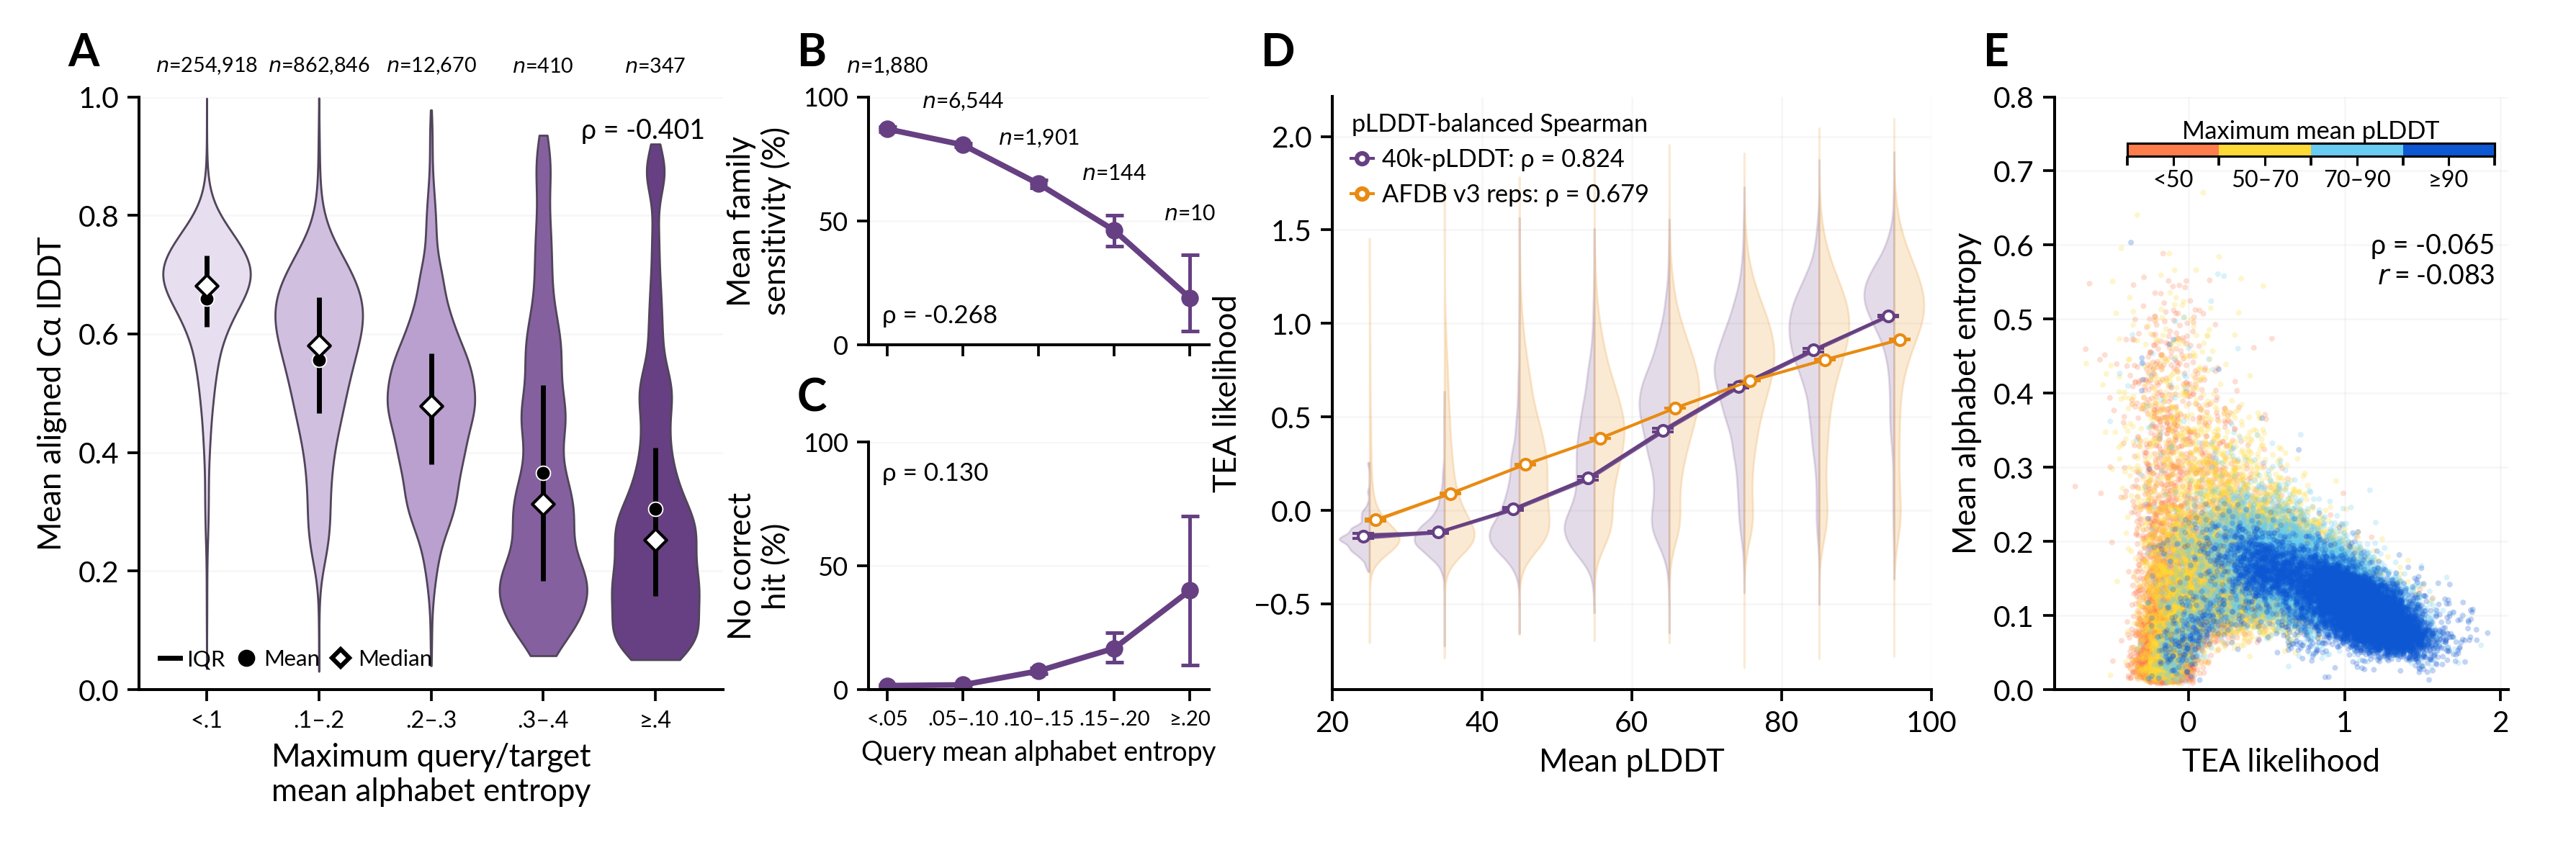

In [2]:
from io import BytesIO
from IPython.display import display, Image as InlineImage
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path('..').resolve()
DATA = ROOT/'data/plot_tables/confidence/figure3'
STYLE = {'font': 'Lato', 'font_size': 7, 'figure_size': (7.95, 2.65), 'dpi': 450,
         'order': '#664082',
         'violin_colors': ['#e7deef', '#d1bfe0', '#baa0cf', '#85609f', '#664082']}
LAYOUT = {'B': (0.43, 0.52, 1.8, 1.83), 'C': (2.68, 1.585, 1.05, 0.765), 'D': (2.68, 0.52, 1.05, 0.765), 'A': (4.11, 0.52, 1.85, 1.83), 'E': (6.34, 0.52, 1.4, 1.83)}
LABEL_MAP = {'B':'A','C':'B','D':'C','A':'D','E':'E'}
PLDDT_COLORS = ['#fd7d4d', '#feda36', '#6accf1', '#0d57d3']
BIN_LABELS = ['<0.1', '0.1–0.2', '0.2–0.3', '0.3–0.4', '≥0.4']
mpl.rcParams.update({'font.family': STYLE['font'], 'font.size': 7,
    'axes.labelsize': 7, 'axes.labelpad': 2.5, 'xtick.labelsize': 6.5,
    'ytick.labelsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': .65, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.major.width': .6, 'ytick.major.width': .6, 'xtick.major.pad': 2,
    'ytick.major.pad': 2, 'legend.frameon': False, 'path.simplify': False})

def panel(fig, rectangle):
    w, h = fig.get_size_inches()
    x, y, width, height = rectangle
    return fig.add_axes([x/w, y/h, width/w, height/h])

def weighted_violin(ax, values, weights, position, color):
    grid = np.linspace(values.min(), values.max(), 160)
    density = gaussian_kde(values, weights=weights, bw_method=.18)(grid)
    order = np.argsort(values, kind='stable')
    cdf = np.cumsum(weights[order])/weights.sum()
    q1, median, q3 = values[order][np.searchsorted(cdf, [.25,.5,.75])]
    mean = np.average(values, weights=weights)
    stats = dict(coords=grid, vals=density, mean=mean, median=median,
                 min=values.min(), max=values.max())
    body = ax.violin([stats], positions=[position], widths=.78,
                    showmeans=False, showmedians=False, showextrema=False)
    body['bodies'][0].set(facecolor=color, edgecolor='#51455a', linewidth=.45, alpha=1)
    ax.vlines(position, q1, q3, color='black', linewidth=1.1)
    ax.scatter(position, mean, s=10, facecolor='black', edgecolor='white', linewidth=.3, zorder=5)
    ax.scatter(position, median, s=12, marker='D', facecolor='white', edgecolor='black', linewidth=.65, zorder=6)


proteins = pd.read_parquet(DATA/'proteins_40k.parquet')
quality = pd.read_parquet(DATA/'afmd_alignment_quality.parquet')
scop = pd.read_csv(DATA/'scop_entropy_bins.tsv', sep='\t')
stats = json.loads((DATA/'statistics.json').read_text())

combined=pd.read_csv(DATA/'combined_plddt_means.tsv',sep='\t')

violin_densities=pd.read_csv(DATA/'combined_plddt_violin_densities.tsv',sep='\t')

panel_correlations=json.loads((DATA/'panel_correlations.json').read_text())
rho=panel_correlations['panels']
balanced_correlations=json.loads((DATA/'plddt_balanced_correlations.json').read_text())
balanced_by_name={row['cohort']:row for row in balanced_correlations['cohorts']}
plddt_rho={'40k pLDDT set':balanced_by_name['40k pLDDT set']['plddt_balanced_spearman'],
           'AFDB cluster reps':balanced_by_name['AFDB v3 cluster reps']['plddt_balanced_spearman']}


fig = plt.figure(figsize=STYLE['figure_size'], dpi=150)
axes = {letter: panel(fig, LAYOUT[letter]) for letter in 'ABCDE'}

# D: split protein-level TL distributions, with exact means and mean CIs.
ax=axes['A']
for name,color,side,offset in [('40k pLDDT set','#664082','low',-.8),
                               ('AFDB cluster reps','#e88b12','high',.8)]:
    part=combined.loc[combined.cohort.eq(name)].sort_values('plddt_bin')
    violin_stats=[]
    for row in part.itertuples():
        density=violin_densities.loc[violin_densities.cohort.eq(name)&violin_densities.plddt_bin.eq(row.plddt_bin)]
        violin_stats.append(dict(coords=density.value.to_numpy(),vals=density.density.to_numpy(),
            mean=row.mean,median=np.nan,min=density.value.min(),max=density.value.max()))
    center=part.plddt_bin.to_numpy()*10+5
    # Matplotlib requires a median entry even when median markers are disabled.
    bodies=ax.violin(violin_stats,positions=center,widths=8,side=side,
        showmeans=False,showmedians=False,showextrema=False)
    for body in bodies['bodies']:
        body.set(facecolor=color,edgecolor=color,alpha=.18,linewidth=.45)
    x=center+offset
    ax.fill_between(x,part.ci_low,part.ci_high,color=color,alpha=.80,linewidth=.35,edgecolor=color,zorder=4)
    interval=np.vstack([part['mean']-part.ci_low,part.ci_high-part['mean']])
    display_name='40k-pLDDT' if name=='40k pLDDT set' else 'AFDB v3 reps'
    label=f"{display_name}: ρ = {plddt_rho[name]:.3f}"
    ax.errorbar(x,part['mean'],yerr=interval,fmt='o-',color=color,lw=.65,ms=2.4,
                markerfacecolor='white',markeredgewidth=.65,elinewidth=.55,capsize=2.4,
                capthick=.55,label=label,zorder=5)
lower=float(violin_densities.value.min());upper=float(violin_densities.value.max())
pad=(upper-lower)*.04
ax.set(xlim=(20,100),ylim=(lower-pad,upper+pad),xticks=[20,40,60,80,100],
       xlabel='Mean pLDDT',ylabel='TEA likelihood')
legend_handles=[Line2D([],[],color=color,lw=.65,marker='o',ms=2.4,mfc='white',
                 label=f"{label}: ρ = {plddt_rho[name]:.3f}")
                 for name,label,color in [('40k pLDDT set','40k-pLDDT','#664082'),
                                          ('AFDB cluster reps','AFDB v3 reps','#e88b12')]]
ax.legend(handles=legend_handles,title='pLDDT-balanced Spearman',title_fontsize=5.5,
          loc='upper left',bbox_to_anchor=(.015,.99),fontsize=5.5,ncol=1,
          handlelength=.9,handletextpad=.35,columnspacing=.7,borderaxespad=0)

# B: uncertainty at the weaker whole-protein endpoint of each alignment.
ax = axes['B']
for index, label in enumerate(BIN_LABELS):
    group = quality[quality.entropy_bin.eq(index)]
    if not len(group):
        ax.text(index+1,1.035,'$n$=0',transform=ax.get_xaxis_transform(),
                ha='center',va='bottom',fontsize=4.6,clip_on=False)
        continue
    weighted_violin(ax,group.mean_aligned_lddt.to_numpy(float),group.weight.to_numpy(float),
                    index+1, STYLE['violin_colors'][index])
    ax.text(index+1,1.035,f'$n$={len(group):,}',transform=ax.get_xaxis_transform(),
            ha='center',va='bottom',fontsize=4.6,clip_on=False)
ax.set(xlim=(.4,5.6),ylim=(0,1),xticks=range(1,6),
       xticklabels=['<.1','.1–.2','.2–.3','.3–.4','≥.4'],
       xlabel='Maximum query/target\nmean alphabet entropy',ylabel='Mean aligned Cα lDDT')
ax.tick_params(axis='x', labelsize=5.2)
ax.text(.97,.965,f"ρ = {rho['A']['spearman']:.3f}",transform=ax.transAxes,
        ha='right',va='top',fontsize=6)
ax.legend(handles=[Line2D([],[],color='black',lw=1.1,label='IQR'),
                   Line2D([],[],color='black',marker='o',ms=2.8,ls='',label='Mean'),
                   Line2D([],[],color='black',marker='D',mfc='white',ms=2.8,ls='',label='Median')],
          loc='lower left',ncol=3,fontsize=5.0,handlelength=.9,handletextpad=.3,columnspacing=.5)

# C/D: group all SCOP targets into fixed entropy bins.
for letter, feature, ylabel in [('C','mean_family_sensitivity_percent','Mean family\nsensitivity (%)'),
                                ('D','no_correct_hit_percent','No correct\nhit (%)')]:
    ax = axes[letter]
    center = scop[feature].to_numpy()
    low, high = scop[feature+'_ci_low'].to_numpy(), scop[feature+'_ci_high'].to_numpy()
    ax.errorbar(range(5),center,yerr=np.vstack([center-low,high-center]),
                color=STYLE['order'],lw=1.25,marker='o',ms=2.9,
                elinewidth=.8,capsize=2,capthick=.8)
    ax.set(xlim=(-.25,4.25),ylim=(0,100),yticks=[0,50,100],xticks=range(5),ylabel=ylabel)
    if letter == 'C':
        ax.set_xticklabels([])
        for index, count in enumerate(scop.queries):
            offset=(0,11) if index==0 else (0,7)
            anchor=high[index]
            ax.annotate(f'$n$={count:,}',xy=(index,anchor),xytext=offset,
                        textcoords='offset points',ha='center',
                        va='bottom',fontsize=4.8)
    else:
        ax.set_xticklabels(['<.05','.05–.10','.10–.15','.15–.20','≥.20'],fontsize=4.7)
        ax.set_xlabel('Query mean alphabet entropy',fontsize=6)
    panel_key=LABEL_MAP[letter]
    ax.text(.04,.07 if letter=='C' else .92,f"ρ = {rho[panel_key]['spearman']:.3f}",
            transform=ax.transAxes,ha='left',va='bottom' if letter=='C' else 'top',fontsize=5.6)
    ax.tick_params(axis='y',labelsize=5.8)

# E: both scores for all 40k proteins; color denotes mean pLDDT.
ax = axes['E']
group = proteins.sort_values('max_plddt',kind='stable')
cmap = mpl.colors.ListedColormap(PLDDT_COLORS)
norm = mpl.colors.BoundaryNorm([0,50,70,90,100],cmap.N)
ax.scatter(group.structural_confidence,group.alphabet_entropy,c=group.max_plddt,
           cmap=cmap,norm=norm,s=1.6,alpha=.25,linewidths=0,rasterized=True)
ax.set(xlabel='TEA likelihood',ylabel='Mean alphabet entropy')
ax.text(.97,.77,f"ρ = {stats['confidence_entropy_spearman']:.3f}\n$r$ = {stats['confidence_entropy_pearson']:.3f}",
        transform=ax.transAxes,ha='right',va='top',fontsize=6)
ax.set_ylim(0,.8)
gax = axes['E'].inset_axes([.16,.90,.81,.022])
gbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap=cmap),cax=gax,
                   orientation='horizontal',spacing='uniform',ticks=[25,60,80,95])
gbar.ax.set_xticklabels(['<50','50–70','70–90','≥90'])
gbar.ax.tick_params(labelsize=5.2,width=.5,length=2,pad=1)
gbar.set_label('Maximum mean pLDDT',fontsize=5.5,labelpad=1)
gbar.ax.xaxis.set_label_position('top')
gbar.outline.set_linewidth(.5)

for letter, ax in axes.items():
    ax.grid(axis='y' if letter in 'BCD' else 'both',alpha=.10,linewidth=.4)
    ax.set_axisbelow(True)
    bounds = ax.get_position(original=True)
    width, height = fig.get_size_inches()
    fig.text(bounds.x0-.22/width,bounds.y1+.07/height,LABEL_MAP[letter],
             ha='left',va='bottom',fontsize=10,fontweight='bold')
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=STYLE['dpi'],facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))